# CLIP ViT-B/32 on a cleaned, class-balanced 10K COCO 2017 split: zero-shot vs fine-tuned

**Task.** Build a 10,000-image split of COCO 2017 (5,000 train, 3,000 test, 2,000 validation), clean it, score a
model zero-shot on all of it, fine-tune on the 5,000 train images, and score again.

**Model.** OpenAI CLIP ViT-B/32. BLIP was the first choice but is not COCO-free: its pretraining included the COCO
train images. CLIP was trained on a private web collection (WIT-400M) with no COCO labels or captions. Nobody outside
OpenAI can prove that collection contains no COCO image, so "COCO-free" here means "not trained on COCO data on purpose".

**Metrics.** CLIP has no captioning head, so the metrics are image-text retrieval (recall, rank, CLIPScore) and
zero-shot classification of the 80 COCO classes from text prompts (average precision, F1). Section 5 adds ranking
metrics (MRR, nDCG, mAP), classification extras, embedding diagnostics, and 1K/3K/5K gallery protocols.

**How to read it.** Sections 1 to 4 follow the order of the work. Every table is read from the saved result files in
`results/task10k/`, so the numbers are the ones the checked runs produced.

In [1]:
import os, sys, subprocess
root = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
os.chdir(root); sys.path.insert(0, root)
import json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from task10k import report
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
# Set to True to recompute everything (about 1.5 h on one GPU). False reads the saved results.
RERUN = False

def run(*args):
    print("$", " ".join(args)); subprocess.run(args, check=True)

if RERUN:
    py = sys.executable
    run(py, "-m", "task10k.clean")
    run(py, "-m", "task10k.split")
    run(py, "-m", "task10k.zeroshot")
    for lr in ("3e-7", "1e-6", "3e-6", "1e-5"):
        run(py, "-m", "task10k.finetune", "--lr", lr, "--out", f"results/task10k/sweep/lr{lr}.json")
    for seed in (0, 1, 2):
        run(py, "-m", "task10k.finetune", "--lr", "1e-6", "--seed", str(seed), "--final",
            "--out", f"results/task10k/final/s{seed}.json")

res = report.load()
zero, finals, sweep = res["zero"], res["finals"], res["sweep"]
print(f"{len(finals)} fine-tuning seeds, {len(sweep)} learning rates in the sweep")

3 fine-tuning seeds, 3 learning rates in the sweep


## 1. Data: cleaning and the three splits

**Cleaning runs in two stages.** The cheap metadata rules run over all 123,287 COCO train2017 and val2017 images.
The slow image checks (full decode, near-duplicate hash) run only on the 10,000 images that were chosen, and a bad
image is replaced by the next candidate.

| Rule | What it does |
|---|---|
| Object labels | An object counts toward an image's label only if it covers at least 0.5% of the image and is not a crowd region. Images left with no label are dropped. |
| Captions | Exactly 5 per image. Whitespace, control characters and unicode forms are normalised; captions under 3 or over 50 words, without letters, or duplicated inside an image are dropped. |
| Size | Images with a side under 128 px are dropped. |
| Decode check | Every chosen image is fully decoded; unreadable files are replaced. Grayscale images are kept and converted to RGB at load. |
| Near-duplicates | A perceptual hash (dHash, Hamming distance of at most 4) over the 10K; the later image of a pair is replaced. No picture appears in two splits. |

In [3]:
display(report.cleaning_table(res["cleaning"]))
sp = res["split"]
print("chosen images:", sp["sizes"], "| near-duplicates replaced while selecting:",
      sp["removed_during_selection"].get("near_duplicate", 0), "| image modes:", sp["image_modes"])

,count
rule,
train2017 images examined,118287
val2017 images examined,5000
removed: no object annotation,1069
removed: only objects under 0.5% of the image,3557
removed: shorter side under 128 px,25
removed: fewer than 5 usable captions,275
captions dropped: duplicates within an image,304
"captions dropped: <3 or >50 words, no letters",0
images kept as candidates,118361


chosen images: {'train': 5000, 'test': 3000, 'val': 2000} | near-duplicates replaced while selecting: 13 | image modes: {'RGB': 9979, 'L': 21}


**The split.**
- **Train (5,000)**: COCO train2017, **class-balanced** by a greedy selector that always takes the image helping the most
  classes still below 150 images, so every class is represented about equally.
- **Test (3,000)**: COCO train2017, disjoint from train, **stratified** (it keeps the natural class mix). It is drawn
  only from images that sit in the Karpathy val/test splits, which BLIP did not train on, so the same split stays clean
  if BLIP is added later.
- **Validation (2,000)**: the official COCO val2017 images, stratified. Used to pick the learning rate and the epoch.

,Gini of class counts,normalised entropy,fewest images in a class,most images in a class
set,,,,
train (balanced),0.082,0.983,75,936
random 5K from the same pool,0.496,0.856,3,2436
val (stratified),0.492,0.857,2,969
test (stratified),0.486,0.860,4,1440


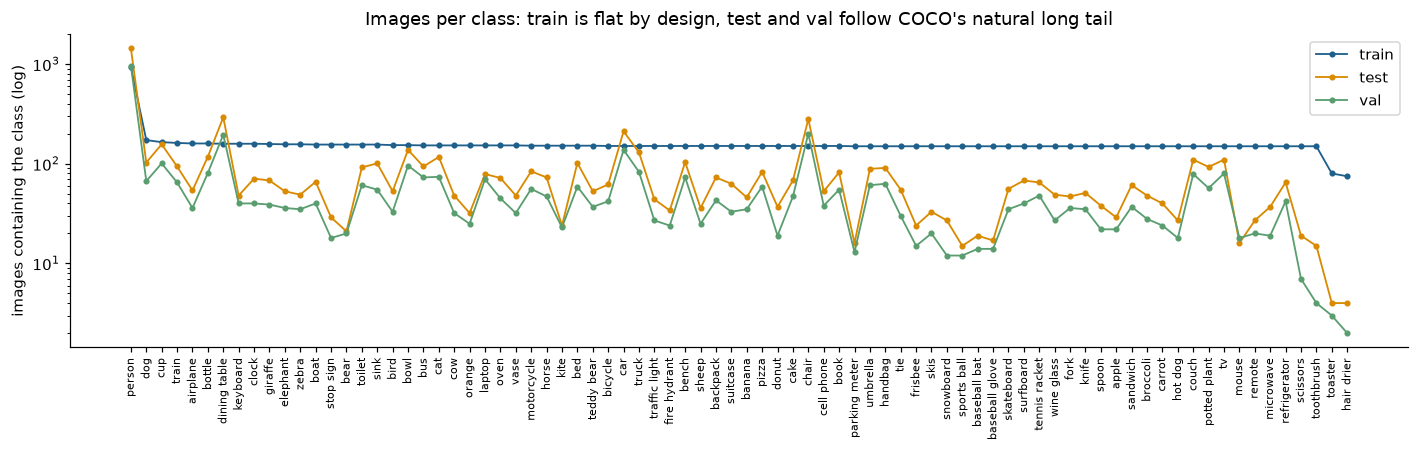

In [4]:
display(report.balance_table(sp))
report.plot_class_counts(sp); plt.show()

Classes with few test or val images (their per-class numbers are noisy):
  toaster      test   4  val   3
  scissors     test  19  val   7
  hair drier   test   4  val   2
  toothbrush   test  15  val   4


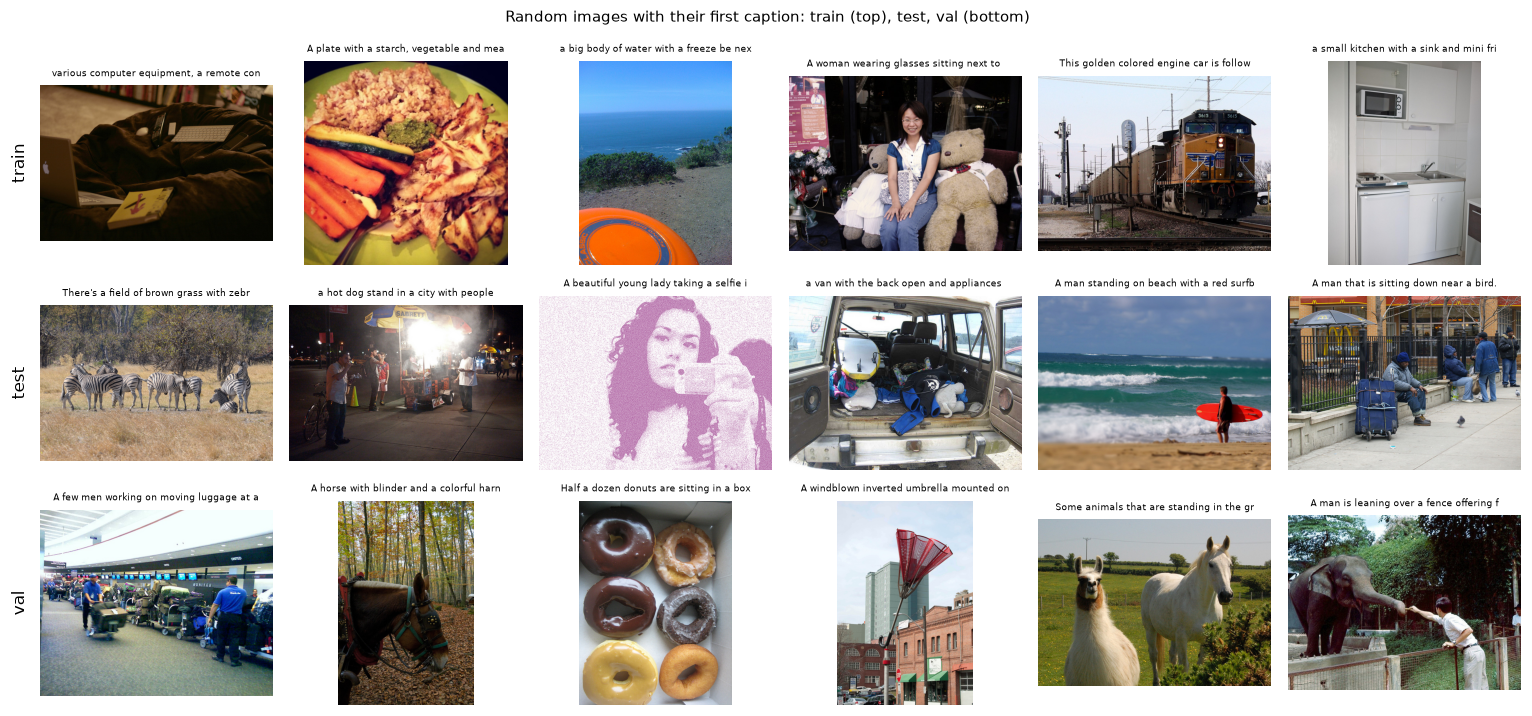

In [5]:
rare = [(c["name"], c["test_images"], c["val_images"]) for c in sp["classes"] if c["test_images"] < 15 or c["val_images"] < 10]
print("Classes with few test or val images (their per-class numbers are noisy):")
for name, t, v in rare: print(f"  {name:12s} test {t:3d}  val {v:3d}")
report.contact_sheet(); plt.show()

## 2. Zero-shot results

CLIP scores every image against every caption. Retrieval is measured per split, with the gallery being that split's own
images and captions (5 per image), and for all 10,000 images together. Intervals are 95% bootstrap intervals over
queries. Classification uses the prompt "a photo of a {class}" for each of the 80 classes; the F1 thresholds are chosen
per class on the validation split and applied to every split, so validation F1 is slightly optimistic.

In [6]:
display(report.metric_table(zero, [{"eval": zero}], "test")[["zero-shot", "zero-shot 95% CI"]].rename_axis("test split, zero-shot"))

,zero-shot,zero-shot 95% CI
"test split, zero-shot",,
image to text R@1,56.5,"[54.6, 58.3]"
image to text R@5,80.1,"[78.7, 81.6]"
image to text R@10,87.5,"[86.3, 88.7]"
text to image R@1,35.8,"[35.1, 36.7]"
text to image R@5,63.2,"[62.4, 63.9]"
text to image R@10,74.0,"[73.3, 74.7]"
rsum,397.1,"[392.7, 401.2]"
image to text median rank,1.00,
image to text mean rank,6.00,


In [7]:
rows = []
for split in report.SPLITS:
    f = report.flat(zero, split)
    rows.append({"split": split, "images": sum(zero["n_images"].values()) if split == "all10k" else zero["n_images"][split],
                 "image to text R@1": f["image to text R@1"], "R@5": f["image to text R@5"],
                 "text to image R@1": f["text to image R@1"], "t2i R@5": f["text to image R@5"],
                 "rsum": f["rsum"], "CLIPScore": round(f["CLIPScore"], 3), "mAP": f["mAP (80 classes)"],
                 "F1 micro": f["F1 micro"], "F1 macro": f["F1 macro"]})
table = pd.DataFrame(rows).set_index("split").round({"image to text R@1": 1, "R@5": 1, "text to image R@1": 1,
                                                       "t2i R@5": 1, "rsum": 1, "CLIPScore": 3, "mAP": 1,
                                                       "F1 micro": 1, "F1 macro": 1})
display(table)
print("Retrieval recall falls as the gallery grows, so compare splits of equal size only. The train split has the "
      "largest single-split gallery (5,000 images), which lowers its recall; whether its balanced content is also "
      "harder is not isolated here.")

,images,image to text R@1,R@5,text to image R@1,t2i R@5,rsum,CLIPScore,mAP,F1 micro,F1 macro
split,,,,,,,,,,
train,5000,45.4,71.2,26.9,51.8,339.2,0.771,47.3,38.8,43.5
val,2000,62.4,84.4,40.2,68.4,425.7,0.760,52.8,54.3,56.1
test,3000,56.5,80.1,35.8,63.2,397.1,0.761,52.8,52.5,50.2
all10k,10000,41.2,66.0,23.4,45.2,307.3,0.766,49.5,45.5,47.8


Retrieval recall falls as the gallery grows, so compare splits of equal size only. The train split has the largest single-split gallery (5,000 images), which lowers its recall; whether its balanced content is also harder is not isolated here.


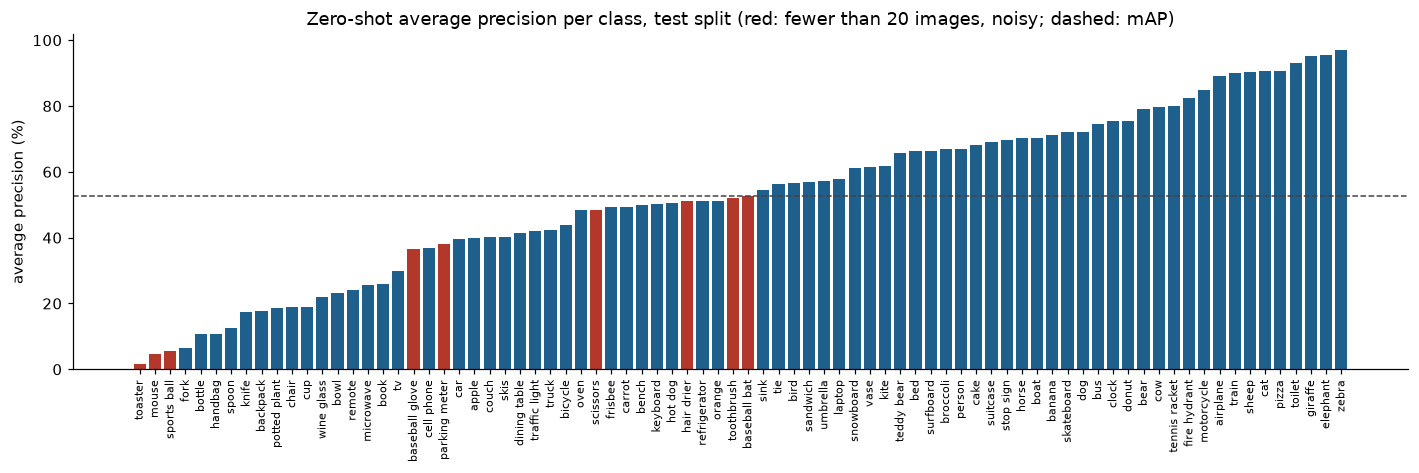

In [8]:
report.plot_per_class_ap(zero, "test"); plt.show()

## 3. Fine-tuning

Everything in CLIP is trained (both towers and the temperature) on the 5,000 train images, which give 25,000
image-caption pairs. The loss is the symmetric contrastive loss in which all captions of the same image count as
positives. AdamW with weight decay 0.1, cosine schedule with 10% warm-up, batch 64, bf16, random-crop and flip
augmentation, at most 10 epochs, and the epoch with the best **validation** retrieval rsum is kept.
The learning rate was picked on validation from a sweep; the test split was not scored until the rate was fixed.
Three seeds at the chosen rate give the mean and spread.

,best epoch,epochs run,best val rsum,final train loss
learning rate,,,,
1e-06,6,8,472.1,0.157
3e-06,4,6,469.3,0.119
1e-05,1,3,447.3,0.198


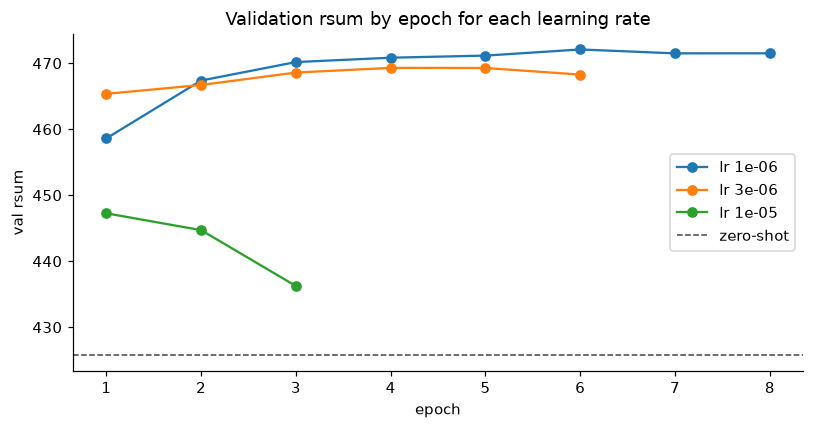

In [9]:
display(report.sweep_table(sweep))
report.plot_sweep(sweep, report.flat(zero, "val")["rsum"]); plt.show()

In [10]:
print("A fourth rate, 3e-7, was started but stopped by the thermal watchdog at epoch 5 (validation rsum 465.9, "
      "still rising slowly, below the 1e-6 run at the same epoch: 471.1). It is not in the table.")
best = max(sweep, key=lambda s: s["best_val_rsum"])
print(f"Chosen learning rate: {best['lr']:g} (best validation rsum {best['best_val_rsum']:.1f}; zero-shot validation rsum "
      f"{report.flat(zero, 'val')['rsum']:.1f}).")
display(pd.DataFrame([{"seed": f["seed"], "best epoch": f["best_epoch"], "epochs run": f["epochs_run"],
                       "val rsum": round(f["best_val_rsum"], 1), "minutes": round(f["train_seconds"] / 60, 1)} for f in finals]).set_index("seed"))

A fourth rate, 3e-7, was started but stopped by the thermal watchdog at epoch 5 (validation rsum 465.9, still rising slowly, below the 1e-6 run at the same epoch: 471.1). It is not in the table.
Chosen learning rate: 1e-06 (best validation rsum 472.1; zero-shot validation rsum 425.7).


,best epoch,epochs run,val rsum,minutes
seed,,,,
0,6,8,472.1,14.8
1,8,10,472.6,18.9
2,6,8,473.6,14.9


## 4. Before and after

The headline comparison is on the **test** split, which was used for nothing but this table. The second table repeats the
main metrics for every split. CLIPScore is not a like-for-like comparison here: fine-tuning changes the scale of the
cosine similarities, so a small change in it says little about quality.

In [11]:
display(report.metric_table(zero, finals, "test"))

,zero-shot,zero-shot 95% CI,"fine-tuned (mean ± std, 3 seeds)",change
metric,,,,
image to text R@1,56.5,"[54.6, 58.3]",62.8 ± 0.4,+6.3
image to text R@5,80.1,"[78.7, 81.6]",86.0 ± 0.1,+5.8
image to text R@10,87.5,"[86.3, 88.7]",92.5 ± 0.3,+5.0
text to image R@1,35.8,"[35.1, 36.7]",47.1 ± 0.3,+11.3
text to image R@5,63.2,"[62.4, 63.9]",74.5 ± 0.2,+11.3
text to image R@10,74.0,"[73.3, 74.7]",84.1 ± 0.1,+10.1
rsum,397.1,"[392.7, 401.2]",447.1 ± 0.8,+49.9
image to text median rank,1.00,,1.00 ± 0.00,+0.0
image to text mean rank,6.00,,4.12 ± 0.07,-1.9


In [12]:
display(report.summary_by_split(zero, finals))

rsum              image to text R@1             text to image R@1             mAP (80 classes)            
       zero-shot   fine-tuned         zero-shot  fine-tuned         zero-shot  fine-tuned        zero-shot  fine-tuned
split                                                                                                                 
train      339.2  441.2 ± 2.4              45.4  59.1 ± 0.4              26.9  43.5 ± 0.4             47.3  53.9 ± 0.1
val        425.7  472.8 ± 0.8              62.4  69.8 ± 0.3              40.2  51.7 ± 0.1             52.8  58.8 ± 0.3
test       397.1  447.1 ± 0.8              56.5  62.8 ± 0.4              35.8  47.1 ± 0.3             52.8  57.3 ± 0.3
all10k     307.3  386.4 ± 1.1              41.2  51.7 ± 0.2              23.4  35.6 ± 0.2             49.5  55.7 ± 0.1

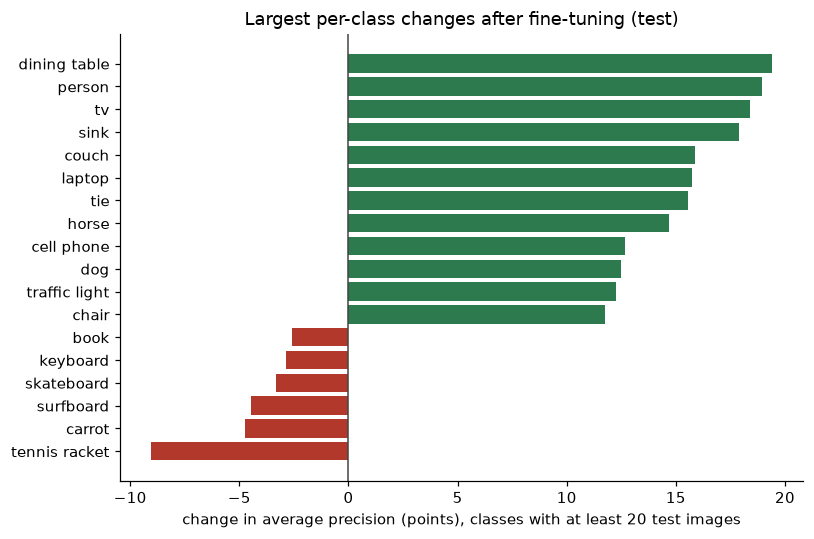

Classes whose average precision dropped (at least 20 test images):


,images in split,AP zero-shot,AP fine-tuned,change
class,,,,
fire hydrant,34,82.5,80.5,-2.0
cow,48,79.6,79.0,-0.5
zebra,49,97.0,95.9,-1.1
backpack,73,17.9,16.7,-1.1
skateboard,56,72.1,68.8,-3.3
surfboard,68,66.5,62.0,-4.5
tennis racket,65,80.1,71.0,-9.0
knife,51,17.4,15.3,-2.1
carrot,40,49.4,44.6,-4.7


In [13]:
pc = report.per_class_table(zero, finals, "test")
report.plot_per_class_change(pc); plt.show()
print("Classes whose average precision dropped (at least 20 test images):")
display(pc[(pc["reliable"]) & (pc["change"] < 0)][["images in split", "AP zero-shot", "AP fine-tuned", "change"]].round(1))

In [14]:
t0, ft = report.flat(zero, "test"), [report.flat(f["eval"], "test") for f in finals]
m = lambda k: report.seed_stats([f[k] for f in ft])
lines = [
  f"**Test rsum** went from {t0['rsum']:.1f} to {m('rsum')[0]:.1f} ± {m('rsum')[1]:.1f} "
  f"(zero-shot 95% interval {report.ci_of(zero, 'test', 'rsum')[0]:.1f} to {report.ci_of(zero, 'test', 'rsum')[1]:.1f}).",
  f"**Image-to-text R@1** {t0['image to text R@1']:.1f} to {m('image to text R@1')[0]:.1f}; "
  f"**text-to-image R@1** {t0['text to image R@1']:.1f} to {m('text to image R@1')[0]:.1f}.",
  f"**Classification mAP** {t0['mAP (80 classes)']:.1f} to {m('mAP (80 classes)')[0]:.1f} ± {m('mAP (80 classes)')[1]:.1f}.",
  *[f"**{lab} (test)** {zero['retrieval_ext']['test'][d][n]:.1f} to "
    f"{report.seed_stats([f['eval']['retrieval_ext']['test'][d][n] for f in finals])[0]:.1f}."
    for lab, d, n in (("Image-to-text MRR", "i2t", "MRR"), ("Text-to-image MRR", "t2i", "MRR"),
                      ("Image-to-text nDCG@10", "i2t", "nDCG@10"), ("Text-to-image nDCG@10", "t2i", "nDCG@10"))],
  f"**Train split rsum** moved from {report.flat(zero,'train')['rsum']:.1f} to "
  f"{report.seed_stats([report.flat(f['eval'],'train')['rsum'] for f in finals])[0]:.1f}; the model has seen these images, "
  f"so it is the in-sample reference, not a result.",
  f"{int((pc['reliable'] & (pc['change'] < 0)).sum())} of {int(pc['reliable'].sum())} classes with at least 20 test images lost average precision.",
]
display(Markdown("### Key results\n\n" + "\n".join("- " + l for l in lines)))

### Key results

- **Test rsum** went from 397.1 to 447.1 ± 0.8 (zero-shot 95% interval 392.7 to 401.2).
- **Image-to-text R@1** 56.5 to 62.8; **text-to-image R@1** 35.8 to 47.1.
- **Classification mAP** 52.8 to 57.3 ± 0.3.
- **Image-to-text MRR (test)** 67.0 to 73.0.
- **Text-to-image MRR (test)** 48.6 to 59.6.
- **Image-to-text nDCG@10 (test)** 49.6 to 58.1.
- **Text-to-image nDCG@10 (test)** 53.8 to 64.9.
- **Train split rsum** moved from 339.2 to 441.2; the model has seen these images, so it is the in-sample reference, not a result.
- 13 of 71 classes with at least 20 test images lost average precision.

## 5. More metrics: ranking quality, classification, embeddings, gallery size

Recall@k only asks whether the correct item is in the top k. The metrics below look at the whole ranking. Relevance is
**exact-match**: an image has 5 correct captions, a caption has 1 correct image, and everything else counts as wrong
(a caption of a similar photo is not credited). All ranking numbers are on a 0 to 100 scale.

| Metric | Definition |
|---|---|
| **MRR** | Mean of 1 / (position of the first correct item). 100 means the correct item is always first. |
| **nDCG@k** | Each correct item in the top k earns 1 / log2(position + 1); the sum is divided by the best possible sum. Rewards putting correct items high. |
| **mAP** | Average precision over all correct items (image to text: 5 captions). For text to image there is one correct item, so mAP equals MRR and is shown once. |
| **Recall-all@k** | Share of an image's 5 correct captions found in the top k. Recall@k in section 4 counts only the best one. |
| **R-Precision** | Precision at k = 5, the number of correct captions. With 5 correct captions it equals Recall-all@5. |
| **Precision@10** | Correct captions in the top 10, divided by 10. It cannot exceed 50 with 5 correct captions. |
| **AUROC** | Chance that a class's score is higher for an image containing it than for one without. 50 is chance. |
| **Label-ranking AP** | For each image, how high its true classes sit in the ranking of all 80 classes. |
| **Label recall@k** | Share of an image's true classes among its k highest-scoring classes. |
| **Head / mid / tail** | Classes split into thirds by how many val+test images contain them (the natural COCO frequency; train is flat by design). |
| **Modality gap** | Distance between the centre of the image embeddings and the centre of the caption embeddings. |
| **Alignment / uniformity** | Alignment: how close matched pairs are (lower is closer). Uniformity: how evenly embeddings spread over the sphere (lower is more spread). |

In [15]:
display(report.ext_retrieval_table(zero, finals, "test").rename_axis("test split"))

,zero-shot,zero-shot 95% CI,"fine-tuned (mean ± std, 3 seeds)",change
test split,,,,
image to text MRR,67.0,"[65.7, 68.4]",73.0 ± 0.2,+6.0
image to text mAP,42.9,"[41.8, 44.0]",51.5 ± 0.1,+8.5
image to text nDCG@5,42.7,"[41.6, 43.9]",50.1 ± 0.1,+7.4
image to text nDCG@10,49.6,"[48.4, 50.7]",58.1 ± 0.0,+8.6
image to text nDCG@50,59.5,"[58.4, 60.5]",67.5 ± 0.1,+8.0
image to text Recall-all@5 (= R-Precision),38.8,"[37.7, 39.8]",46.1 ± 0.1,+7.3
image to text Recall-all@10,51.2,"[50.0, 52.4]",60.7 ± 0.1,+9.5
image to text Recall-all@50,77.3,"[76.4, 78.3]",85.2 ± 0.1,+7.9
image to text Precision@10,25.6,"[25.0, 26.2]",30.3 ± 0.0,+4.7


image to text MRR             image to text nDCG@10             text to image MRR             text to image nDCG@10            
               zero-shot  fine-tuned             zero-shot  fine-tuned         zero-shot  fine-tuned             zero-shot  fine-tuned
split                                                                                                                                 
train               57.1  70.7 ± 0.3                  39.2  54.7 ± 0.3              39.0  57.6 ± 0.5                  43.7  63.7 ± 0.5
val                 72.3  78.5 ± 0.1                  54.5  63.2 ± 0.2              53.1  64.1 ± 0.1                  58.7  69.4 ± 0.0
test                67.0  73.0 ± 0.2                  49.6  58.1 ± 0.0              48.6  59.6 ± 0.2                  53.8  64.9 ± 0.2
all10k              52.6  63.2 ± 0.2                  35.2  46.1 ± 0.1              34.2  48.3 ± 0.3                  38.2  53.5 ± 0.3

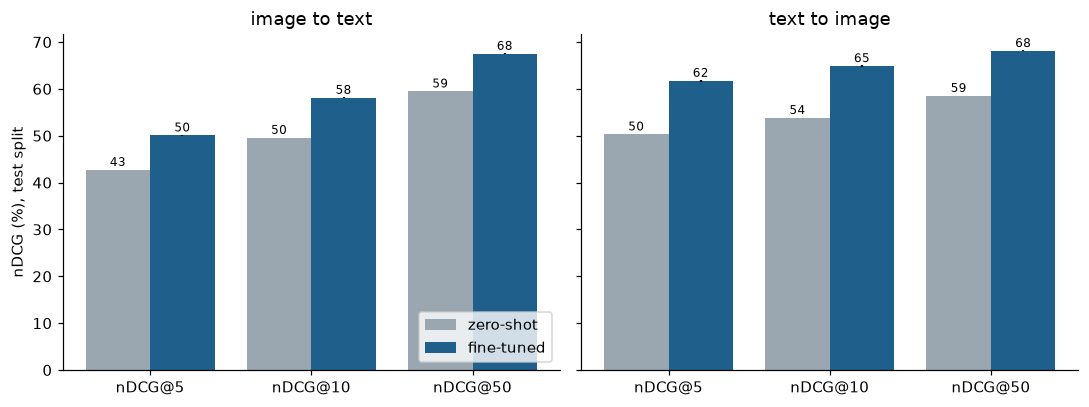

In [16]:
display(report.ext_summary_by_split(zero, finals))
report.plot_ndcg(zero, finals, "test"); plt.show()

**Gallery size.** Recall falls as the gallery grows, so numbers from a 1,000-image gallery are not comparable with
numbers from a 3,000-image one. The usual COCO protocol uses 1K galleries; the table gives the test split as three
disjoint 1K galleries (mean over the folds), as the full 3K gallery, and as a 5K gallery made of validation plus test
images. The 5K gallery includes validation images, which were used to pick the epoch, so its fine-tuned numbers are
slightly less independent.

In [17]:
display(report.protocol_table(zero, finals))

1K gallery (test, mean of 3 folds)              3K gallery (full test)              5K gallery (val + test)             
                                               zero-shot   fine-tuned              zero-shot   fine-tuned               zero-shot   fine-tuned
metric                                                                                                                                        
image to text R@1                                   70.6   76.5 ± 0.3                   56.5   62.8 ± 0.4                    49.6   57.4 ± 0.1
text to image R@1                                   50.2   61.5 ± 0.2                   35.8   47.1 ± 0.3                    30.0   40.7 ± 0.2
rsum                                               473.3  512.0 ± 0.2                  397.1  447.1 ± 0.8                   358.6  411.9 ± 0.2
image to text MRR                                   79.3   84.1 ± 0.2                   67.0   73.0 ± 0.2                    60.8   68.0 ± 0.1
text to image MRR                                   63.1   72.9 ± 0.1                   48.6   59.6 ± 0.2                    42.1   53.0 ± 0.1
image to text nDCG@10                               64.2   72.3 ± 0.1                   49.6   58.1 ± 0.0                    43.0   51.5 ± 0.1
text to image nDCG@10                               68.8   78.0 ± 0.1                   53.8   64.9 ± 0.2                    46.8   58.1 ± 0.1

**Classification, beyond mAP.** Same prompts and the same validation-picked thresholds as section 2.

In [18]:
display(report.cls_extras_table(zero, finals, "test").rename_axis("test split, 80 classes"))
print("Worst classes after fine-tuning (at least 20 test images):")
display(report.worst_classes_table(zero, finals, "test"))

,zero-shot,"fine-tuned (mean ± std, 3 seeds)",change
"test split, 80 classes",,,
mean AUROC,91.7,93.5 ± 0.1,+1.8
label-ranking AP,68.6,77.1 ± 0.2,+8.5
top-1 class is correct,78.2,83.5 ± 0.1,+5.3
label recall@3,63.8,73.9 ± 0.3,+10.1
label recall@5,74.1,83.7 ± 0.4,+9.6
sample-wise F1,55.6,61.5 ± 0.5,+5.9
micro precision,47.0,56.3 ± 1.7,+9.3
micro recall,59.6,60.5 ± 0.7,+0.9
Hamming loss,3.0,2.4 ± 0.1,-0.6


Worst classes after fine-tuning (at least 20 test images):


,images in split,AP zero-shot,AP fine-tuned,change
class,,,,
handbag,91,10.8,11.3,0.6
bottle,118,10.6,13.1,2.4
fork,47,6.6,14.4,7.8
knife,51,17.4,15.3,-2.1
backpack,73,17.9,16.7,-1.1
spoon,38,12.4,18.9,6.5
potted plant,93,18.6,19.9,1.3
book,82,25.8,23.3,-2.6
wine glass,49,21.9,25.2,3.3


**What fine-tuning does to the embeddings.** CLIP's image and caption embeddings sit in two separate regions
(the modality gap). The table shows whether training closes it, how much closer matched pairs get, and whether the
temperature moved.

In [19]:
display(report.diagnostics_table(zero, finals, "test").rename_axis("test split"))

,zero-shot,"fine-tuned (mean ± std, 3 seeds)",change
test split,,,
"cosine, matched pairs",0.305,0.299 ± 0.001,-0.005
"cosine, unmatched pairs",0.151,0.102 ± 0.003,-0.049
margin (matched - unmatched),0.154,0.198 ± 0.003,+0.044
modality gap,0.827,0.852 ± 0.010,+0.025
alignment (lower is tighter),1.391,1.402 ± 0.002,+0.011
"uniformity, images (lower is more spread)",-2.043,-1.941 ± 0.034,+0.102
"uniformity, captions",-1.855,-2.170 ± 0.055,-0.315
logit scale (1 / temperature),100.000,100.000 ± 0.000,+0.000


## 6. Caveats

- **CLIP's training data is private.** The model was not trained on COCO labels or captions, but its web data may
  contain COCO images. The zero-shot numbers could be slightly optimistic for that reason.
- **Small classes are noisy.** Toaster, hair drier, toothbrush and scissors have only a handful of test and validation
  images, so their per-class numbers move a lot. They are flagged in the charts.
- **Balanced train, natural test.** Balancing the train set deliberately departs from COCO's class mix, so the model
  sees rare classes far more often than the test set does. A model fine-tuned on a natural mix could behave differently.
- **Validation is used twice.** It picks the learning rate and the epoch, and the classification thresholds come from it,
  so its numbers are the least independent. Test and train are not used for any choice.
- **Three seeds** give a rough spread, not a tight interval.
- **Exact-match relevance.** The ranking metrics treat any caption or image other than the original as wrong, so they
  understate quality when another caption also describes the picture well. A graded notion of relevance (for example by
  shared object labels) was not used.
- **Not covered:** captioning (CLIP cannot caption) and BLIP. The split was built so BLIP can be scored on it later.